# 12 · English Learning Events (synthetic): pre-processing and EDA

Supports thesis Section 4.2 (*English Learning Events*). **The log is synthetic**: a documented generator produced it, so every pattern below describes the generator, not real learners.

The same steps as notebooks 10–11: raw events → answer events → pyKT inputs, then the same descriptive statistics and plots. It also verifies that the five-model workspace (`data/benchmarks/english_kt/kt`, dataset name `english_bench`) holds **exactly** the split of the curated run in `data/processed/` (which the curated DKT/SAKT/AKT checkpoints were trained on).

**Where to run.** Locally (recommended): `.venv-kt` with `requirements-analysis.txt`, started from the repository; no GPU needed.
**On Colab (CPU runtime is enough):** upload `ednet_colab_bundle.zip` (built by `knowledge_tracing/make_colab_bundle.py`) to `MyDrive/ednet_kt1/`; the training runs already live in `MyDrive/ednet_kt1/data/benchmarks/` (for the English run, upload `data/benchmarks/english_kt/` there too). Then *Runtime → Run all*: the first cell mounts Drive, unpacks the bundle and links the benchmark folder. Figures and tables are written to `data/benchmarks/report/` (on Drive when on Colab).

In [1]:
import sys, os
if "google.colab" in sys.modules:
    !pip install -q seaborn
from pathlib import Path
_root = Path.cwd().resolve()
while not (_root / "knowledge_tracing").is_dir() and _root.parent != _root:
    _root = _root.parent
if "google.colab" in sys.modules and not (_root / "knowledge_tracing").is_dir():
    import zipfile
    from google.colab import drive
    drive.mount("/content/drive")
    import time as _t
    with zipfile.ZipFile("/content/drive/MyDrive/ednet_kt1/ednet_colab_bundle.zip") as zf:
        for _i in zf.infolist():   # keep the zip's timestamps: the runner compares mtimes
            _p = zf.extract(_i, "/content/ednet")
            _m = _t.mktime(_i.date_time + (0, 0, -1))
            os.utime(_p, (_m, _m))
    _root = Path("/content/ednet")
sys.path[:0] = [str(_root), str(_root / "knowledge_tracing")]
import report_utils as ru
ROOT = ru.setup()
ru.style()
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
pd.set_option("display.width", 160, "display.max_columns", 30)
print("repository:", ROOT)

repository: /home/rene/MicroLearningThesis


In [2]:
import eda, hashlib
raw = pd.read_csv("data/raw/english_learning_events.csv", encoding="utf-8-sig")
print(f"raw rows: {len(raw):,}")
display(raw.head())

raw rows: 138,523


,learner_id,session_id,event_index,item_id,kc_id,kc_dimension,event_type,timestamp,response_time_s,correct,hint_count,switch_count,change_count
0,L0001,S001,1,Q00519,KC024,grammar,answer,1696897529,10.19,1.0,0,0,0
1,L0001,S001,2,Q01350,KC060,reading,answer,1696897604,5.39,1.0,0,0,0
2,L0001,S001,3,Q01176,KC053,vocabulary,answer_change,1696897651,NaN,NaN,0,0,0
3,L0001,S001,4,Q01189,KC053,vocabulary,answer,1696897655,10.74,1.0,0,0,1
4,L0001,S001,5,Q02001,KC088,writing,answer,1696897688,9.18,1.0,0,0,0


## 1. Raw events
The log mixes answers with other learning events. Only answer events with a binary outcome enter the models.

In [3]:
et = raw["event_type"].value_counts().rename_axis("event type").reset_index(name="rows")
display(et)
ru.save_table(et, "english_event_types", "English Learning Events: raw event types (synthetic)", "tab:english-events", align="lr")

,event type,rows
0,answer,75006
1,hint_request,26216
2,answer_change,21770
3,choice_switch,15531


table  -> data/benchmarks/report/tables/english_event_types.tex


In [4]:
a = eda.answers_only(raw)
ov = eda.overview(a)
display(pd.Series(ov).to_frame("value"))
for c in ("hint_count", "switch_count", "change_count"):
    if c in a:
        print(f"{c}: share of answers with >0 = {(a[c] > 0).mean():.3f}")

,value
learners,1200.0000
answers,75006.0000
items,2189.0000
KCs,96.0000
dimensions,4.0000
correct rate,0.6783
mean answers per learner,62.5100
median answers per learner,52.0000


hint_count: share of answers with >0 = 0.265
switch_count: share of answers with >0 = 0.175
change_count: share of answers with >0 = 0.232


## 2. Pre-processing and split check

In [5]:
WS = Path("data/benchmarks/english_kt/kt")
def sha(p): return hashlib.sha256(Path(p).read_bytes()).hexdigest()[:16]
checks = []
for f in ["processed/split_assignments.csv", "processed/question_map.csv", "processed/concept_map.csv"]:
    cur, ws = Path("data/processed") / Path(f).name, WS / f
    checks.append({"file": Path(f).name, "curated": sha(cur) if cur.exists() else "missing",
                   "workspace": sha(ws) if ws.exists() else "missing"})
for f in ["train_valid_sequences.csv", "test_sequences.csv"]:
    cur, ws = Path("data/processed/pykt_english") / f, WS / "pykt" / f
    checks.append({"file": f, "curated": sha(cur) if cur.exists() else "missing",
                   "workspace": sha(ws) if ws.exists() else "missing"})
chk = pd.DataFrame(checks); chk["identical"] = chk["curated"] == chk["workspace"]
display(chk)
assert chk["identical"].all(), "the workspace split differs from the curated split"
sp = pd.read_csv(WS / "processed/split_assignments.csv")
cov = eda.split_coverage(a, sp)
display(pd.Series(cov).to_frame("value"))
ru.save_table(pd.DataFrame([cov]).T.reset_index().rename(columns={"index": "check", 0: "value"}),
              "english_split", "English Learning Events: learner-level split (70/10/20)", "tab:english-split", align="lr")

,file,curated,workspace,identical
0,split_assignments.csv,e4fc6a991e4fa7f7,e4fc6a991e4fa7f7,True
1,question_map.csv,27353c6880964207,27353c6880964207,True
2,concept_map.csv,390c44ffbac772e8,390c44ffbac772e8,True
3,train_valid_sequences.csv,af0d5c082ef80eb8,af0d5c082ef80eb8,True
4,test_sequences.csv,c4ab6470db765f56,c4ab6470db765f56,True


,value
train learners,840.0
valid learners,120.0
test learners,240.0
learners in more than one split,0.0
test answers,14963.0
test answers on items unseen in train,0.0
test items unseen in train,0.0
test answers on KCs unseen in train,0.0


table  -> data/benchmarks/report/tables/english_split.tex


## 3. Descriptive statistics

,quantity,n,mean,sd,min,Q1,median,Q3,max
0,Answers per learner,1200.0,62.505,45.970,8.000,26.000,52.000,79.000,185.000
1,Accuracy per learner,1200.0,0.672,0.175,0.125,0.567,0.684,0.806,1.000
2,Answers per item,2189.0,34.265,9.456,14.000,28.000,33.000,40.000,75.000
3,Accuracy per item,2189.0,0.671,0.267,0.000,0.448,0.750,0.897,1.000
4,Answers per KC,96.0,781.312,86.160,614.000,716.250,777.000,838.750,979.000
5,Accuracy per KC,96.0,0.676,0.252,0.090,0.461,0.749,0.879,0.997
6,Response time (s),75006.0,8.266,4.074,1.500,5.390,7.400,10.170,42.460


table  -> data/benchmarks/report/tables/english_describe.tex


figure -> data/benchmarks/report/figures/english_distributions.png


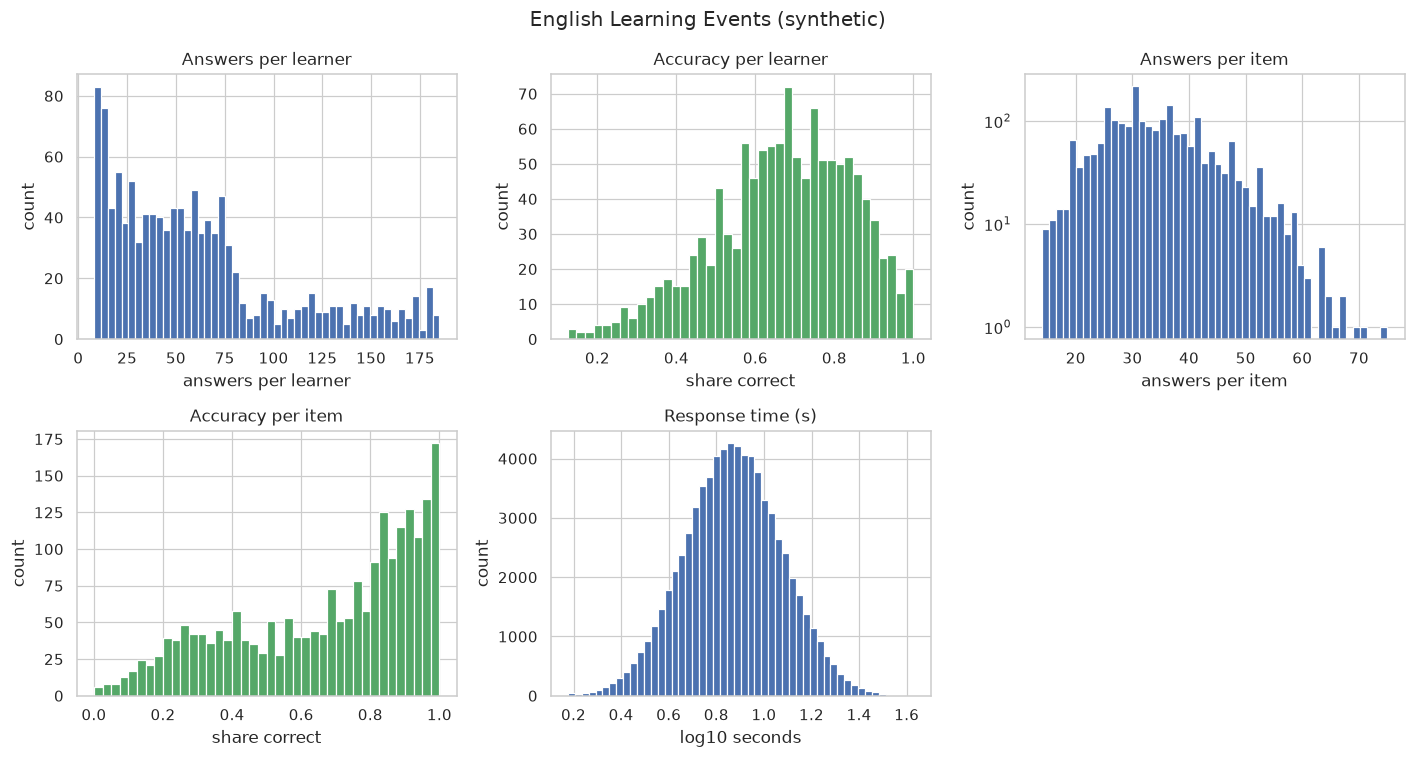

In [6]:
desc = eda.describe_table(a)
display(desc.round(3))
ru.save_table(desc, "english_describe", "Descriptive statistics, English Learning Events (synthetic)",
              "tab:english-describe", digits=2, align="lrrrrrrrr", size="footnotesize")
fig = eda.plot_distributions(a, "English Learning Events (synthetic)")
ru.save_fig(fig, "english_distributions"); plt.show()

figure -> data/benchmarks/report/figures/english_kc_longtail.png


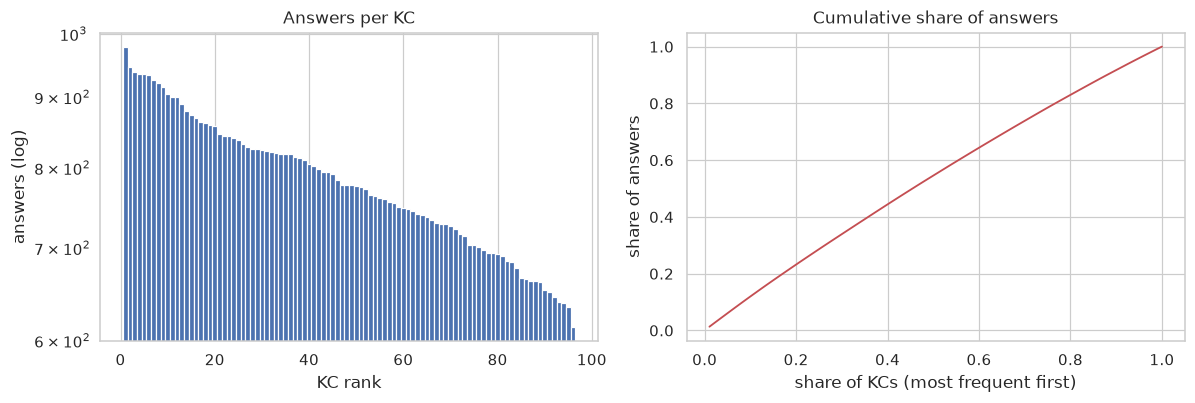

the 10% most frequent KCs carry 12.4% of the answers


,skill,answers,items,KCs,correct rate,median response time (s)
0,grammar,22491,600,28,0.7001,7.3
1,reading,17834,549,24,0.6418,7.8
2,vocabulary,22736,614,26,0.7001,7.2
3,writing,11945,426,18,0.6503,7.6


table  -> data/benchmarks/report/tables/english_by_dimension.tex


figure -> data/benchmarks/report/figures/english_by_dimension.png


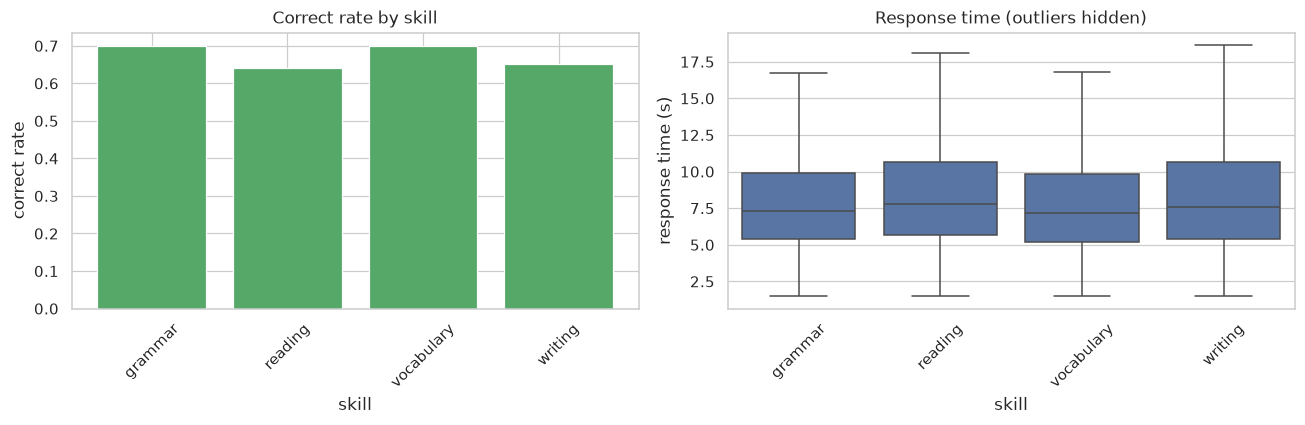

In [7]:
fig, top10 = eda.kc_longtail(a); ru.save_fig(fig, "english_kc_longtail"); plt.show()
print(f"the 10% most frequent KCs carry {top10:.1%} of the answers")
dim = eda.by_dimension(a).rename(columns={"kc_dimension": "skill"})
display(dim)
ru.save_table(dim, "english_by_dimension", "English Learning Events by skill (synthetic)", "tab:english-by-dim", digits=3)
fig = eda.plot_by_dimension(a, "skill"); ru.save_fig(fig, "english_by_dimension"); plt.show()

figure -> data/benchmarks/report/figures/english_accuracy_by_position.png


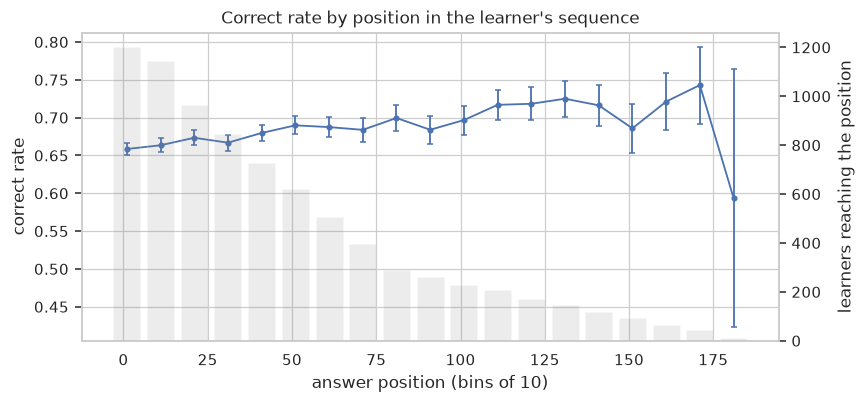

figure -> data/benchmarks/report/figures/english_learner_correlation.png


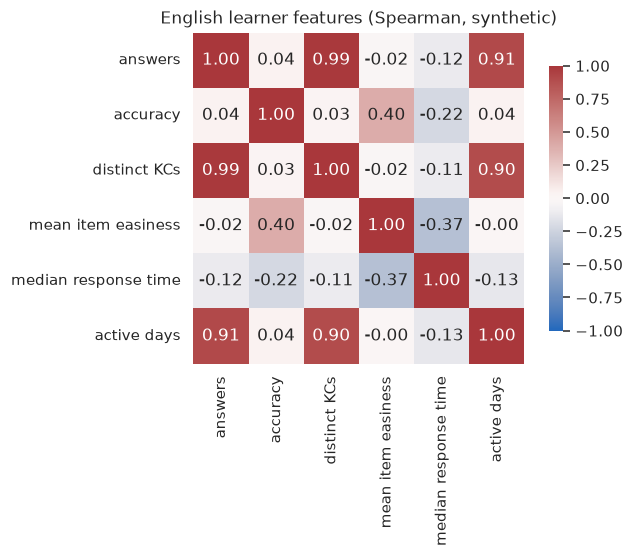

In [8]:
fig, pos = eda.accuracy_by_position(a, width=10, max_pos=200)
ru.save_fig(fig, "english_accuracy_by_position"); plt.show()
feat = eda.learner_features(a)
fig, corr = eda.plot_correlation(feat, "English learner features (Spearman, synthetic)")
ru.save_fig(fig, "english_learner_correlation"); plt.show()

## 4. EdNet-KT1 and English side by side
The two logs are not comparable as populations (real vs generated); the table only shows how different the modelling problems are.

In [9]:
ed = eda.overview(eda.answers_only(pd.read_csv("data/external/ednet/kt1_events_5000.csv")))
side = pd.DataFrame({"EdNet-KT1 (5,000 cohort)": ed, "English Learning Events": ov}).reset_index(names="")
display(side)
ru.save_table(side, "kt_datasets_side_by_side", "The two benchmark logs", "tab:kt-datasets-gen", digits=3, align="lrr")

,,"EdNet-KT1 (5,000 cohort)",English Learning Events
0,learners,5000.0000,1200.0000
1,answers,452335.0000,75006.0000
2,items,11423.0000,2189.0000
3,KCs,143.0000,96.0000
4,dimensions,7.0000,4.0000
5,correct rate,0.6026,0.6783
6,mean answers per learner,90.4700,62.5100
7,median answers per learner,51.0000,52.0000


table  -> data/benchmarks/report/tables/kt_datasets_side_by_side.tex
